# 02 · Modelagem, avaliação e previsão

**Pergunta:** dado tudo o que se sabe sobre uma rota até o fim deste mês, quantos passageiros ela terá no mês que vem?

Este notebook percorre as decisões do pipeline `anac-demanda treinar` e lê os resultados salvos; não retreina nada.

> Pré-requisito: `anac-demanda tudo` na raiz do projeto.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

from anac_demanda.config import carregar_config
from anac_demanda.data import carregar_dados
from anac_demanda.features import carregar_painel

cfg = carregar_config()
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
FIG = cfg.dir_figuras
import json

from anac_demanda.evaluation import calcular_metricas
from anac_demanda.models import BASELINES, ModeloPrevisao
from anac_demanda.splits import dividir

metricas = json.loads((cfg.dir_relatorios / "metricas.json").read_text(encoding="utf-8"))

## 1. Divisão temporal

A divisão é feita pelo **mês previsto**, nunca aleatória: o modelo sempre é avaliado em meses posteriores aos que viu.

| Conjunto | Uso |
|---|---|
| Treino (até 2022) | ajustar os modelos |
| Validação (2023) | escolher modelo e tratamento da COVID |
| Teste (2024–2025) | avaliação final |
| Monitoramento (2026) | meses publicados depois do congelamento do modelo |
| Produção | último mês da base: o alvo ainda não existe |

In [2]:
painel = carregar_painel(cfg)
d = dividir(painel, cfg)
pd.Series(d.resumo(), name="linhas").to_frame()

,linhas
treino,527054
validacao,18917
teste,38117
monitoramento,6728
producao,1587


## 2. Baselines primeiro

Antes de qualquer modelo, quatro regras simples. Repetir o mês atual é bem melhor que repetir o mesmo mês do ano
anterior: o nível recente da rota informa mais do que a sazonalidade sozinha.

In [3]:
pd.DataFrame({n: calcular_metricas(d.validacao["alvo"], f(d.validacao)) for n, f in BASELINES.items()}).T.sort_values("WAPE")

,WAPE,MAE,RMSE,vies
Ingênuo (repete o mês atual),0.148,852.091,"1,630.486",-0.001
Ingênuo com ajuste sazonal,0.178,"1,026.640","2,000.105",0.022
Sazonal x crescimento recente,0.206,"1,189.718","2,196.196",0.022
Sazonal (repete o mesmo mês do ano anterior),0.249,"1,438.325","2,634.408",-0.102


## 3. Escolha do modelo (validação 2023)

O vencedor prevê a **variação** `r = pax[t+1] / pax[t]` com Gradient Boosting, perda absoluta e peso `pax[t]`.
Como `WAPE = Σ pax[t]·|r̂ − r| / Σ pax[t+1]`, o erro minimizado no treino é exatamente a métrica de avaliação.
Modelar a variação também aproveita o ponto forte do baseline ingênuo (o nível atual) e foca o aprendizado no que ele
não captura: sazonalidade da rota, mudanças de oferta e tendência.

In [4]:
pd.DataFrame(metricas["validacao"]).set_index("modelo")

,tipo,WAPE,MAE,RMSE,vies
modelo,,,,,
"Gradient Boosting (variação, perda absoluta)",modelo,0.123,710.908,"1,389.138",-0.009
"Gradient Boosting (variação, perda quadrática)",modelo,0.125,720.496,"1,390.478",-0.012
Gradient Boosting (Poisson),modelo,0.128,740.789,"1,494.751",-0.010
Gradient Boosting (log),modelo,0.146,841.835,"1,579.179",-0.062
Ingênuo (repete o mês atual),baseline,0.148,852.091,"1,630.486",-0.001
Ingênuo com ajuste sazonal,baseline,0.178,"1,026.640","2,000.105",0.022
Sazonal x crescimento recente,baseline,0.206,"1,189.718","2,196.196",0.022
Sazonal (repete o mesmo mês do ano anterior),baseline,0.249,"1,438.325","2,634.408",-0.102
Ridge (log),modelo,0.278,"1,603.984","3,574.311",0.063


In [5]:
c = metricas["covid"]
print(f"Treino com COVID: WAPE {c['WAPE_com_covid']:.2%} · sem COVID: {c['WAPE_sem_covid']:.2%} "
      f"→ decisão ({c['decidido_por']}): {'remover' if c['remover'] else 'manter'}")

Treino com COVID: WAPE 12.32% · sem COVID: 12.27% → decisão (validação): remover


## 4. Teste (2024–2025)

,tipo,WAPE,MAE,RMSE,vies
modelo,,,,,
"Gradient Boosting (variação, perda absoluta)",modelo,0.111,701.067,"1,467.192",-0.006
Ingênuo (repete o mês atual),baseline,0.133,840.916,"1,690.983",-0.001
Ingênuo com ajuste sazonal,baseline,0.163,"1,027.516","2,187.485",0.018
Sazonal x crescimento recente,baseline,0.186,"1,178.600","2,424.509",0.013
Sazonal (repete o mesmo mês do ano anterior),baseline,0.223,"1,408.124","2,720.101",-0.060


Redução de erro frente ao baseline: 16.6%


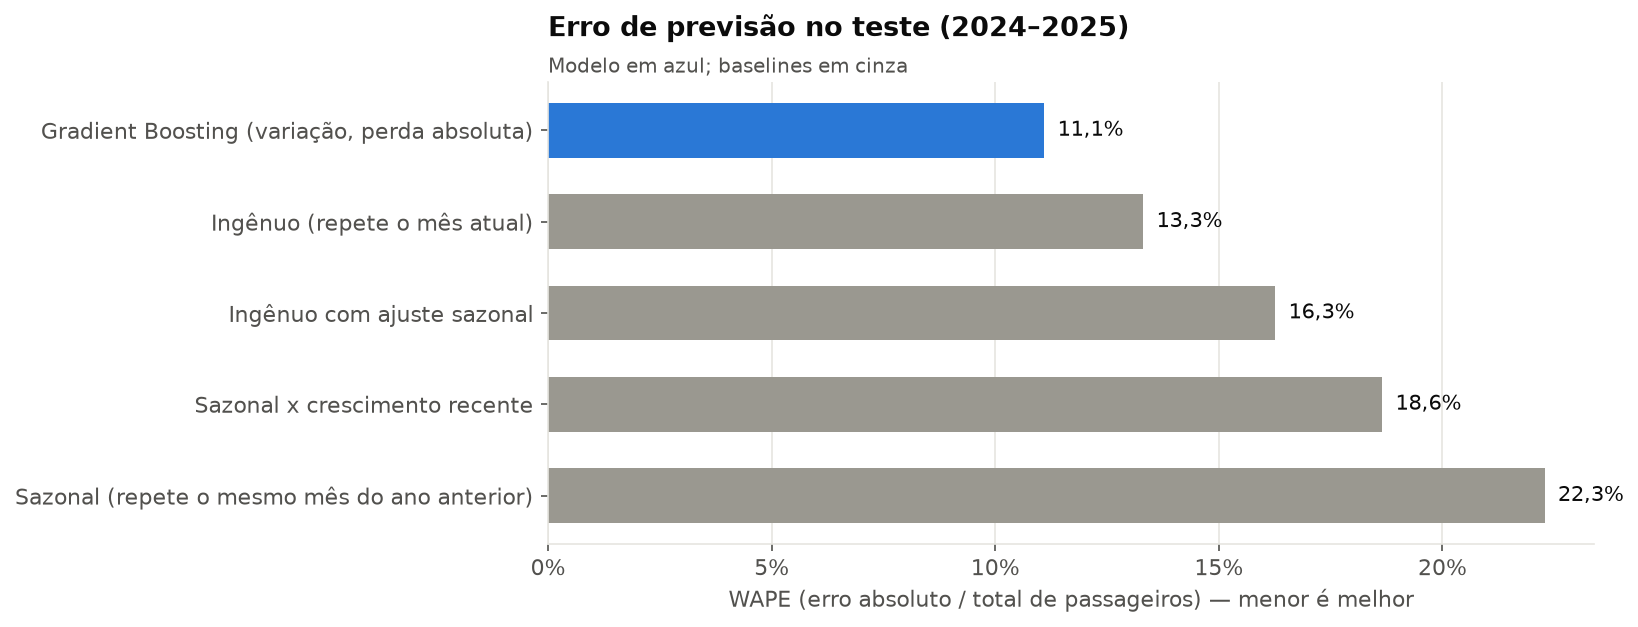

In [6]:
teste = pd.DataFrame(metricas["teste"]).set_index("modelo")
display(teste)
print(f"Redução de erro frente ao baseline: {metricas['reducao_erro_teste']:.1%}")
display(Image(FIG / "resultado_teste.png", width=760))

O maior ganho aparece nas viradas sazonais, justamente onde repetir o mês atual falha. Somando as previsões de todas as rotas:

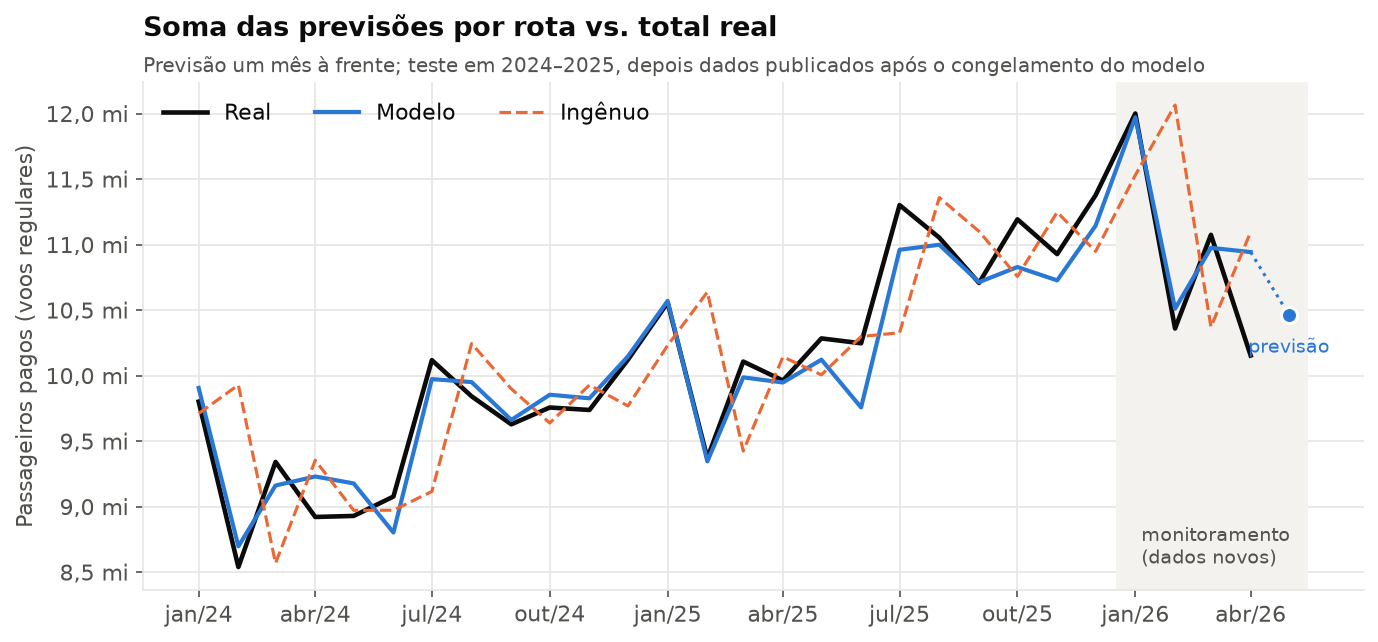

In [7]:
display(Image(FIG / "serie_total.png", width=820))

In [8]:
aval = pd.read_parquet(cfg.dir_previsoes / "previsoes_avaliacao.parquet")
mensal = aval.groupby(["conjunto", "ano_alvo", "mes_alvo"]).apply(
    lambda g: pd.Series({"WAPE modelo": calcular_metricas(g.alvo, g.previsto_modelo)["WAPE"],
                         "WAPE ingênuo": calcular_metricas(g.alvo, g.previsto_baseline)["WAPE"]}),
    include_groups=False)
mensal.style.format("{:.1%}").highlight_min(axis=1, color="#d7e6f8")

## 5. Por porte de rota e o que o modelo usa

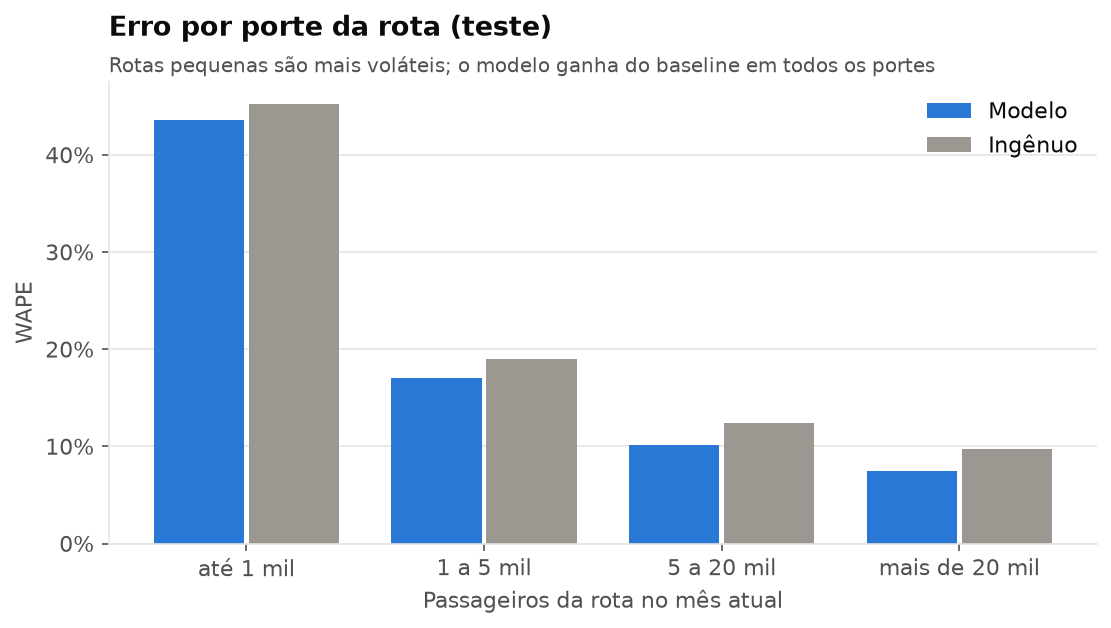

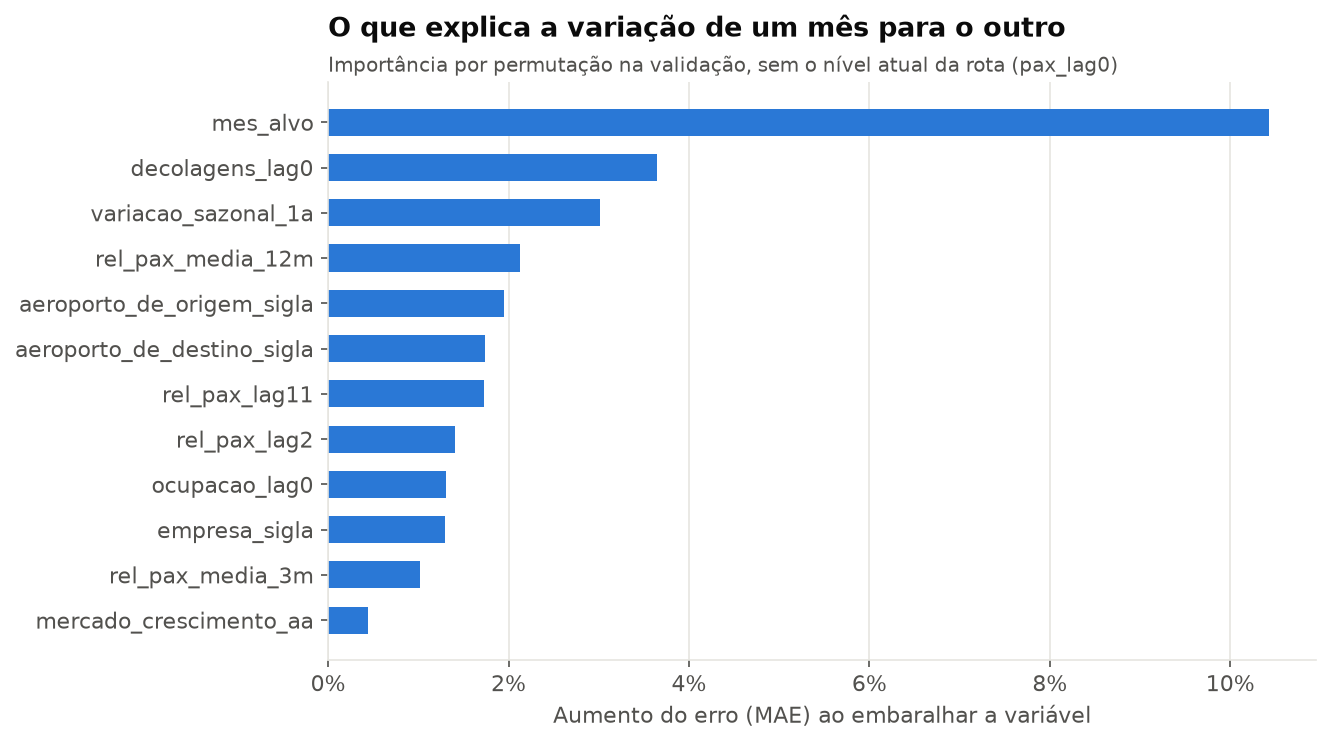

In [9]:
display(Image(FIG / "erro_por_porte.png", width=700))
display(Image(FIG / "importancia_features.png", width=660))

## 6. Onde o modelo erra

Em **maio de 2024**, a enchente no Rio Grande do Sul fechou o aeroporto Salgado Filho (SBPA). Nenhum modelo baseado
apenas no histórico antecipa um choque assim:

In [10]:
poa = aval[(aval.aeroporto_de_origem_sigla == "SBPA") | (aval.aeroporto_de_destino_sigla == "SBPA")]
poa.groupby(["ano_alvo", "mes_alvo"])[["alvo", "previsto_modelo", "previsto_baseline"]].sum().loc[(2024, slice(3, 6)), :].round(0)

alvo  previsto_modelo  previsto_baseline
ano_alvo mes_alvo                                                
2024     3        570,266.000      527,365.000        474,891.000
         4        540,819.000      568,921.000        570,388.000
         5         38,648.000      581,934.000        541,399.000
         6              0.000       41,526.000         38,733.000

## 7. Monitoramento e previsão de produção

O modelo de produção foi treinado com meses até dez/2025 e salvo em `artifacts/`. Os meses de 2026 publicados depois
disso medem o desempenho em dados realmente novos. Por fim, `anac-demanda prever` gera a previsão do mês seguinte ao
último publicado.

In [11]:
mon = metricas["monitoramento"]
print(f"Monitoramento {mon['inicio']} a {mon['fim']}: WAPE modelo {mon['modelo']['WAPE']:.1%} "
      f"· baseline {mon['baseline']['WAPE']:.1%}")
modelo = ModeloPrevisao.carregar(cfg.dir_artefatos / "modelo.joblib")
print("Modelo:", modelo.nome, "· treinado até", modelo.metadados["treinado_ate"])
previsoes = pd.read_csv(sorted(cfg.dir_previsoes.glob("previsoes_20*.csv"))[-1])
print(f"Previsão de {previsoes['mes_previsto'].iloc[0]}: {previsoes['previsao'].sum():,} passageiros em {len(previsoes):,} rotas")
previsoes.head(10)

Monitoramento 2026-01 a 2026-04: WAPE modelo 12.5% · baseline 17.3%


Modelo: Gradient Boosting (variação, perda absoluta) · treinado até 2025-12
Previsão de 2026-05: 10,461,212 passageiros em 1,587 rotas


,empresa_sigla,aeroporto_de_origem_sigla,aeroporto_de_destino_sigla,aeroporto_de_origem_regiao,aeroporto_de_destino_regiao,natureza,mes_base,passageiros_mes_base,mes_previsto,previsao,variacao_prevista,previsao_ingenua
0,GLO,SBSP,SBRJ,SUDESTE,SUDESTE,DOMÉSTICA,2026-04,71170,2026-05,75220,0.057,71170
1,GLO,SBRJ,SBSP,SUDESTE,SUDESTE,DOMÉSTICA,2026-04,70195,2026-05,74761,0.065,70195
2,TAM,SBRJ,SBSP,SUDESTE,SUDESTE,DOMÉSTICA,2026-04,61274,2026-05,65803,0.074,61274
3,TAM,SBSP,SBRJ,SUDESTE,SUDESTE,DOMÉSTICA,2026-04,60758,2026-05,65511,0.078,60758
4,TAM,SBBR,SBSP,CENTRO-OESTE,SUDESTE,DOMÉSTICA,2026-04,44348,2026-05,46586,0.051,44348
5,TAM,SBSP,SBBR,SUDESTE,CENTRO-OESTE,DOMÉSTICA,2026-04,42632,2026-05,45487,0.067,42632
6,TAM,SBPA,SBSP,SUL,SUDESTE,DOMÉSTICA,2026-04,41393,2026-05,41584,0.005,41393
7,TAM,SBSP,SBPA,SUDESTE,SUL,DOMÉSTICA,2026-04,40995,2026-05,40894,-0.003,40995
8,TAM,SBPA,SBGR,SUL,SUDESTE,DOMÉSTICA,2026-04,37358,2026-05,39198,0.049,37358
9,TAM,SBGR,SBPA,SUDESTE,SUL,DOMÉSTICA,2026-04,35843,2026-05,37793,0.054,35843


## Limitações e próximos passos

- Só prevê rotas ativas no mês atual; rotas que reabrem depois de uma pausa ficam de fora.
- Horizonte de um mês; planejamento de malha pediria 3 a 6 meses (previsão direta por horizonte).
- Sem variáveis externas (feriados móveis, eventos, malha anunciada) e sem intervalo de previsão (regressão quantílica).
- Rotas pequenas (< 1 mil passageiros/mês) seguem muito voláteis.